In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment setup ready!")

Environment setup ready!


In [2]:
df = pd.read_csv("supply_chain_data.csv")

print("Dataset Shape (Rows, Columns):", df.shape)
print("\n--- Columns List ---")
print(df.columns.tolist())

df.head()

Dataset Shape (Rows, Columns): (100, 24)

--- Columns List ---
['Product type', 'SKU', 'Price', 'Availability', 'Number of products sold', 'Revenue generated', 'Customer demographics', 'Stock levels', 'Lead times', 'Order quantities', 'Shipping times', 'Shipping carriers', 'Shipping costs', 'Supplier name', 'Location', 'Lead time', 'Production volumes', 'Manufacturing lead time', 'Manufacturing costs', 'Inspection results', 'Defect rates', 'Transportation modes', 'Routes', 'Costs']


,Product type,SKU,Price,Availability,Number of products sold,Revenue generated,Customer demographics,Stock levels,Lead times,Order quantities,...,Location,Lead time,Production volumes,Manufacturing lead time,Manufacturing costs,Inspection results,Defect rates,Transportation modes,Routes,Costs
0,haircare,SKU0,69.808006,55,802,8661.996792,Non-binary,58,7,96,...,Mumbai,29,215,29,46.279879,Pending,0.226410,Road,Route B,187.752075
1,skincare,SKU1,14.843523,95,736,7460.900065,Female,53,30,37,...,Mumbai,23,517,30,33.616769,Pending,4.854068,Road,Route B,503.065579
2,haircare,SKU2,11.319683,34,8,9577.749626,Unknown,1,10,88,...,Mumbai,12,971,27,30.688019,Pending,4.580593,Air,Route C,141.920282
3,skincare,SKU3,61.163343,68,83,7766.836426,Non-binary,23,13,59,...,Kolkata,24,937,18,35.624741,Fail,4.746649,Rail,Route A,254.776159
4,skincare,SKU4,4.805496,26,871,2686.505152,Non-binary,5,3,56,...,Delhi,5,414,3,92.065161,Fail,3.145580,Air,Route A,923.440632


In [3]:
# NEEDED COLS
cols_needed = [
    'Product type', 
    'SKU', 
    'Lead times', 
    'Number of products sold', 
    'Stock levels', 
    'Shipping carriers'
]

df_sub = df[cols_needed].copy()
df_sub.head()

,Product type,SKU,Lead times,Number of products sold,Stock levels,Shipping carriers
0,haircare,SKU0,7,802,58,Carrier B
1,skincare,SKU1,30,736,53,Carrier A
2,haircare,SKU2,10,8,1,Carrier B
3,skincare,SKU3,13,83,23,Carrier C
4,skincare,SKU4,3,871,5,Carrier A


In [4]:
# Missing values check
print("--- Missing Values ---")
print(df_sub.isnull().sum())

# Numerical summary (Min, Max, Mean check)
print("\n--- Summary Statistics ---")
display(df_sub.describe())

# Check negative stock
negative_stock = (df_sub['Stock levels'] < 0).sum()
print(f"\nNegative stock records: {negative_stock}")

--- Missing Values ---
Product type               0
SKU                        0
Lead times                 0
Number of products sold    0
Stock levels               0
Shipping carriers          0
dtype: int64

--- Summary Statistics ---


,Lead times,Number of products sold,Stock levels
count,100.000000,100.000000,100.000000
mean,15.960000,460.990000,47.770000
std,8.785801,303.780074,31.369372
min,1.000000,8.000000,0.000000
25%,8.000000,184.250000,16.750000
50%,17.000000,392.500000,47.500000
75%,24.000000,704.250000,73.000000
max,30.000000,996.000000,100.000000



Negative stock records: 0


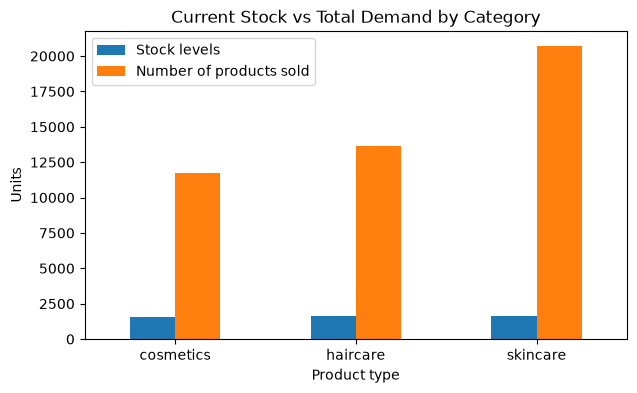

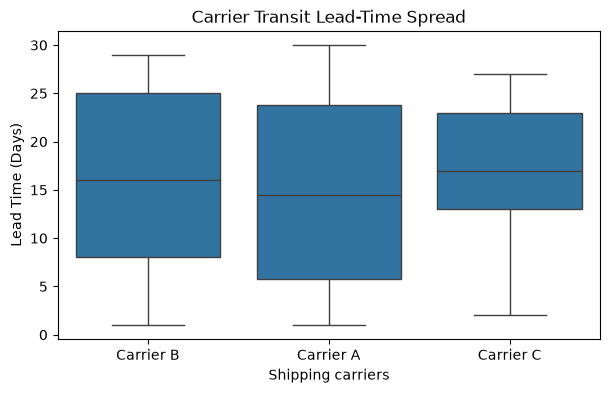

In [5]:
# 1. Total Stock vs Total Demand across categories
category_agg = df_sub.groupby('Product type')[['Stock levels', 'Number of products sold']].sum()
category_agg.plot(kind='bar', figsize=(7, 4))
plt.title("Current Stock vs Total Demand by Category")
plt.ylabel("Units")
plt.xticks(rotation=0)
plt.show()

# 2. Transporter Lead Time Volatility
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_sub, x='Shipping carriers', y='Lead times')
plt.title("Carrier Transit Lead-Time Spread")
plt.ylabel("Lead Time (Days)")
plt.show()

In [6]:
# 1. Category-wise statistics calculate karein
stats = df_sub.groupby('Product type').agg(
    Avg_Transit_Days=('Lead times', 'mean'),
    Transit_StdDev=('Lead times', 'std'),
    Avg_Daily_Demand=('Number of products sold', 'mean'),
    Demand_StdDev=('Number of products sold', 'std'),
    Current_Inventory=('Stock levels', 'sum')
).reset_index()

# 2. Formula variables define karein (Z = 1.65 for 95% service level / OTIF)
Z_FACTOR = 1.65

variance_from_demand = stats['Avg_Transit_Days'] * (stats['Demand_StdDev'] ** 2)
variance_from_transit = (stats['Avg_Daily_Demand'] ** 2) * (stats['Transit_StdDev'] ** 2)

# Safety Stock aur Reorder Point compute karein
stats['Dynamic_Safety_Stock'] = np.ceil(Z_FACTOR * np.sqrt(variance_from_demand + variance_from_transit))
stats['Dynamic_ROP'] = np.ceil((stats['Avg_Daily_Demand'] * stats['Avg_Transit_Days']) + stats['Dynamic_Safety_Stock'])

# 3. Stock status classification
conditions = [
    stats['Current_Inventory'] <= stats['Dynamic_Safety_Stock'],
    stats['Current_Inventory'] <= stats['Dynamic_ROP'],
    stats['Current_Inventory'] > (stats['Dynamic_ROP'] * 2.5)
]
choices = [
    "CRITICAL: Stockout Risk (OOS)",
    "WARNING: Reorder Triggered",
    "NORM BREACH: Overstocked"
]

stats['Inventory_Status'] = np.select(conditions, choices, default="HEALTHY: Optimal Buffer")
stats

,Product type,Avg_Transit_Days,Transit_StdDev,Avg_Daily_Demand,Demand_StdDev,Current_Inventory,Dynamic_Safety_Stock,Dynamic_ROP,Inventory_Status
0,cosmetics,15.384615,9.291187,452.192308,263.207298,1525,7139.0,14096.0,CRITICAL: Stockout Risk (OOS)
1,haircare,15.529412,9.189043,400.323529,306.919368,1644,6390.0,12607.0,CRITICAL: Stockout Risk (OOS)
2,skincare,16.700000,8.259261,518.275000,321.734322,1608,7389.0,16045.0,CRITICAL: Stockout Risk (OOS)


In [7]:
final_master_df = pd.merge(df_sub, stats, on='Product type', how='left')
final_master_df.to_csv("supply_chain_inventory_final.csv", index=False)

print("Single Master CSV successfully generated: 'supply_chain_inventory_final.csv'")
final_master_df.head()

Single Master CSV successfully generated: 'supply_chain_inventory_final.csv'


,Product type,SKU,Lead times,Number of products sold,Stock levels,Shipping carriers,Avg_Transit_Days,Transit_StdDev,Avg_Daily_Demand,Demand_StdDev,Current_Inventory,Dynamic_Safety_Stock,Dynamic_ROP,Inventory_Status
0,haircare,SKU0,7,802,58,Carrier B,15.529412,9.189043,400.323529,306.919368,1644,6390.0,12607.0,CRITICAL: Stockout Risk (OOS)
1,skincare,SKU1,30,736,53,Carrier A,16.700000,8.259261,518.275000,321.734322,1608,7389.0,16045.0,CRITICAL: Stockout Risk (OOS)
2,haircare,SKU2,10,8,1,Carrier B,15.529412,9.189043,400.323529,306.919368,1644,6390.0,12607.0,CRITICAL: Stockout Risk (OOS)
3,skincare,SKU3,13,83,23,Carrier C,16.700000,8.259261,518.275000,321.734322,1608,7389.0,16045.0,CRITICAL: Stockout Risk (OOS)
4,skincare,SKU4,3,871,5,Carrier A,16.700000,8.259261,518.275000,321.734322,1608,7389.0,16045.0,CRITICAL: Stockout Risk (OOS)
